# Guide with deterministic transforms

In [1]:
import pyro
import pyro.distributions as dist
import pyro.distributions.transforms as transforms
import pyro.distributions.constraints as constraints
import pyro.infer as infer
import pyro.optim as optim
import torch

import matplotlib.pyplot as plt

import logging
import math

logging.basicConfig(format='%(message)s', level=logging.INFO)

param_store = pyro.get_param_store()

In [6]:
def model(*args, **kwargs):
    y = pyro.sample("y", dist.Normal(-2, 5))
    return {"y":y}

def deterministic_guide(*args, **kwargs):
    x_loc = pyro.param("x_loc", torch.tensor(0.0))
    x_scale = pyro.param("x_scale", torch.tensor(1.0), constraints.positive)
    x = pyro.sample("x", dist.LogNormal(x_loc, x_scale), infer = {"is_auxiliary":True})
    # The log_density parameter is necessary to get the correct fit. 
    tmp = torch.log(x)
    y = pyro.sample("y", dist.Delta(tmp*2 + 1, log_density = tmp - math.log(2)))
    return {"y":y}

def deterministic_guide2(*args, delta = 0.01, **kwargs):
    x_loc = pyro.param("x_loc", torch.tensor(0.0))
    x_scale = pyro.param("x_scale", torch.tensor(1.0), constraints.positive)
    x = pyro.sample("x", dist.LogNormal(x_loc, x_scale), infer = {"is_auxiliary":True}) 
    # Using built-in bijective transforms gives automatic log prob adjustment
    y = pyro.sample(
        "y", 
        dist.TransformedDistribution(
            dist.Delta(x),
            [
                transforms.ExpTransform().inv,
                transforms.AffineTransform(loc=1, scale=2)
            ]
        )
    )
    return {"y":y}

In [3]:
def do_svi(svi, *args, num_steps = 10000, **kwargs):
    losses = []
    for _ in range(num_steps):
        loss = svi.step(*args, **kwargs)
        losses.append(loss)
    return losses

def print_params():
    for name,val in pyro.get_param_store().items():
        print(f"{name}: {val}")

x_loc: -1.4797440767288208
x_scale: 2.5207161903381348
y mean = -2.0213358402252197, std = 5.023277282714844, shape = torch.Size([10000])


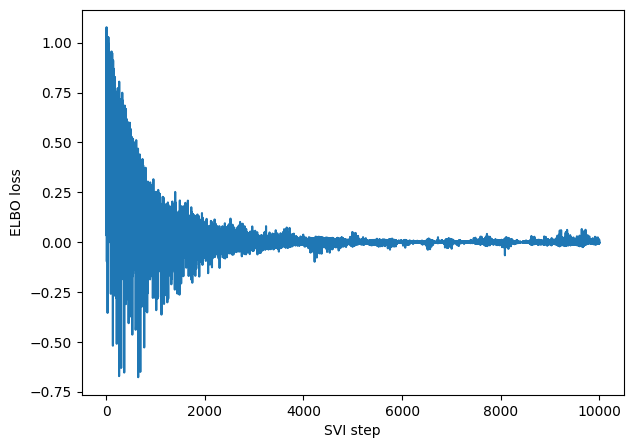

In [4]:
# Test deterministic transform guide
# Expect x_loc = -1.5, x_scale = 2.5

svi = infer.SVI(model, deterministic_guide, optim.Adam({"lr": 0.001}), infer.Trace_ELBO(num_particles=5))

with param_store.scope() as simple_scope:
    losses = do_svi(svi)
    print_params()
    pred = infer.Predictive(model, guide=deterministic_guide, num_samples = 10000, return_sites = ["y"])
    samples = pred.get_samples()['y']
    print(f"y mean = {samples.mean()}, std = {samples.std()}, shape = {samples.shape}")
    

plt.figure(figsize=(7,5))
plt.plot(losses)
plt.xlabel("SVI step")
plt.ylabel("ELBO loss");

x_loc: -1.5004547834396362
x_scale: 2.4849889278411865
y mean = -2.032076835632324, std = 4.909730911254883, shape = torch.Size([10000])


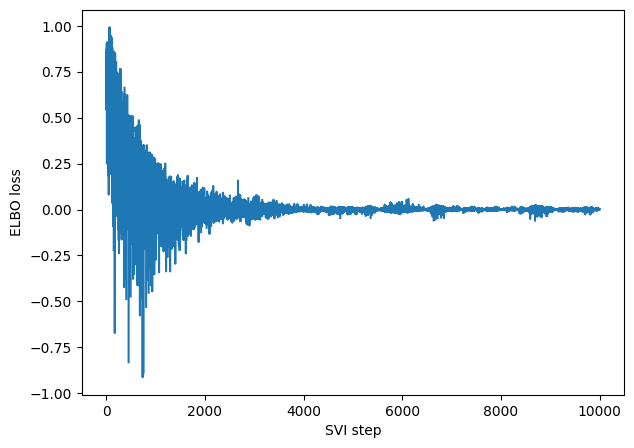

In [5]:
# Test deterministic transform guide with auto-adjustment
# Expect x_loc = -1.5, x_scale = 2.5

svi = infer.SVI(model, deterministic_guide2, optim.Adam({"lr": 0.001}), infer.Trace_ELBO(num_particles=5))

with param_store.scope() as simple_scope:
    losses = do_svi(svi)
    print_params()
    pred = infer.Predictive(model, guide=deterministic_guide2, num_samples = 10000, return_sites = ["y"])
    samples = pred.get_samples()['y']
    print(f"y mean = {samples.mean()}, std = {samples.std()}, shape = {samples.shape}")
    

plt.figure(figsize=(7,5))
plt.plot(losses)
plt.xlabel("SVI step")
plt.ylabel("ELBO loss");